In [17]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns


from scipy import stats

df = pd.read_csv("Block2-task1-data.csv")

df.head()

,Unnamed: 0,StudyNum,Condition,Story,Response,EmpathyQ_1
0,1,1,AI,No consent to share,I'm so sorry to hear about the distressing tim...,9
1,2,1,AI,No consent to share,I'm so sorry to hear about your mum's accident...,9
2,3,1,AI,I was having a really difficult time with work...,I'm really sorry to hear about the immense str...,6
3,4,1,AI,I recently moved into my new house for univers...,I'm really sorry that you're having to experie...,9
4,5,1,AI,"Last week, I walked the kids to school and on ...",I'm truly sorry to hear about what happened to...,9


In [18]:
print(df.shape)

df.info()


print("\n  Missing values per column:")
print(df.isna().sum())


print("\n Duplicated rows:", df.duplicated().sum())

(725, 6)
<class 'pandas.DataFrame'>
RangeIndex: 725 entries, 0 to 724
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  725 non-null    int64
 1   StudyNum    725 non-null    int64
 2   Condition   725 non-null    str  
 3   Story       725 non-null    str  
 4   Response    724 non-null    str  
 5   EmpathyQ_1  725 non-null    int64
dtypes: int64(3), str(3)
memory usage: 34.1 KB

  Missing values per column:
Unnamed: 0    0
StudyNum      0
Condition     0
Story         0
Response      1
EmpathyQ_1    0
dtype: int64

 Duplicated rows: 0


In [19]:
print(df["Condition"].value_counts(dropna=False))
print()


print(df["StudyNum"].value_counts(dropna=False))
print()


print(df["EmpathyQ_1"].describe())

print("\n  Ratings outside 0-9:", (~df["EmpathyQ_1"].between(0, 9)).sum())


print("For Unique responses we have:", df["Response"].nunique(), "of", len(df))



print(' For stories with "No consent to share" we get:', (df["Story"] == "No consent to share").sum())

Condition
AI       371
Human    354
Name: count, dtype: int64

StudyNum
1    725
Name: count, dtype: int64

count    725.000000
mean       7.742069
std        1.723564
min        0.000000
25%        7.000000
50%        8.000000
75%        9.000000
max        9.000000
Name: EmpathyQ_1, dtype: float64

  Ratings outside 0-9: 0
For Unique responses we have: 722 of 725
 For stories with "No consent to share" we get: 203


In [20]:

df = df.drop(columns=["Unnamed: 0"])



df.head()

,StudyNum,Condition,Story,Response,EmpathyQ_1
0,1,AI,No consent to share,I'm so sorry to hear about the distressing tim...,9
1,1,AI,No consent to share,I'm so sorry to hear about your mum's accident...,9
2,1,AI,I was having a really difficult time with work...,I'm really sorry to hear about the immense str...,6
3,1,AI,I recently moved into my new house for univers...,I'm really sorry that you're having to experie...,9
4,1,AI,"Last week, I walked the kids to school and on ...",I'm truly sorry to hear about what happened to...,9


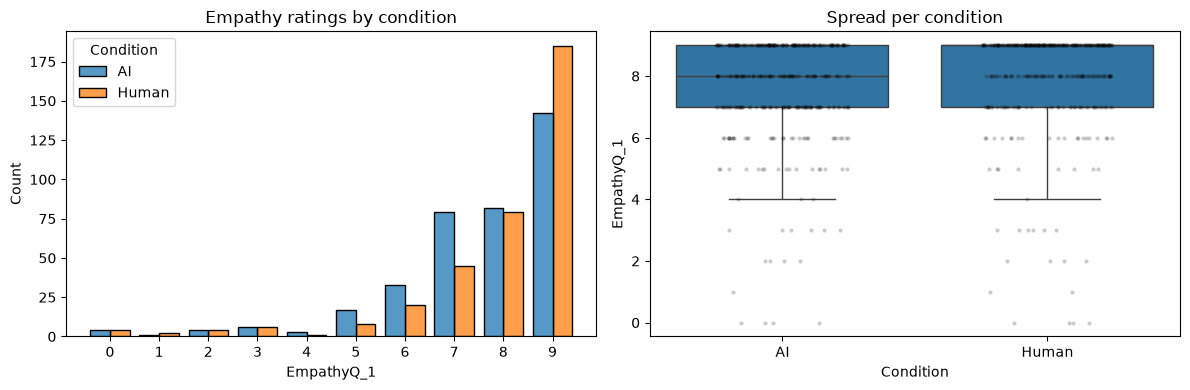

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="EmpathyQ_1", hue="Condition", multiple="dodge",
             discrete=True, shrink=0.8, ax=axes[0])



axes[0].set_title("Empathy ratings by condition")

axes[0].set_xticks(range(0, 10))

sns.boxplot(data=df, x  ="Condition", y="EmpathyQ_1", ax=axes[1], showfliers=False)



sns.stripplot(data=df, x="Condition", y ="EmpathyQ_1", ax=axes[1],
              color="black", alpha=0.2, jitter=0.25, size=3)


axes[1].set_title("Spread per condition")


plt.tight_layout()



plt.show()

In [22]:
print(df.groupby("Condition")["EmpathyQ_1"].agg(["count", "mean", "std", "median"]).round(2))






           count  mean   std  median
Condition                           
AI           371  7.57  1.71     8.0
Human        354  7.92  1.72     9.0


In [23]:
g_ai    = df.loc[df["Condition"] == "AI", "EmpathyQ_1"]

g_human = df.loc[df["Condition"] == "Human", "EmpathyQ_1"]   

print(len(g_ai), len(g_human))

371 354


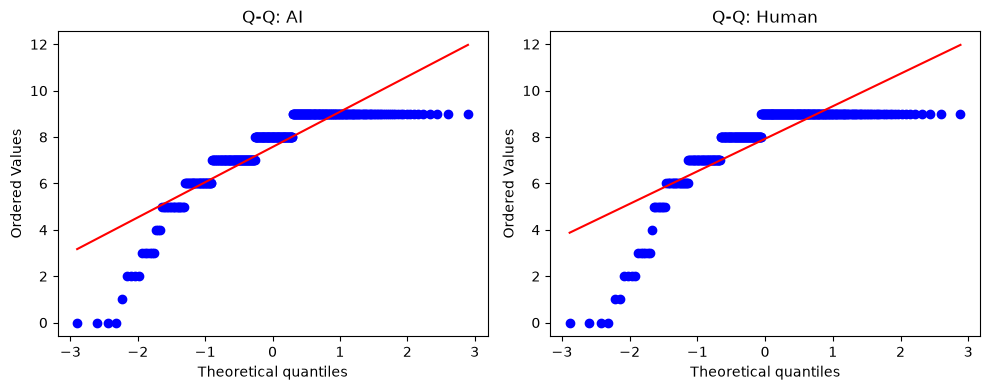

  Shapiro AI:    ShapiroResult(statistic=np.float64(0.7778880550083808), pvalue=np.float64(4.256357936134874e-22))
 Shapiro Human : ShapiroResult(statistic=np.float64(0.6589198651270114), pvalue=np.float64(4.893878186485165e-26))
Levene:        LeveneResult(statistic=np.float64(1.0380776731790229), pvalue=np.float64(0.30860978398040656))
SDs : 1.71 1.72


In [24]:
g_ai    = df.loc[df["Condition"] == "AI", "EmpathyQ_1"]



g_human = df.loc[df["Condition"] == "Human", "EmpathyQ_1"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

stats.probplot(g_ai, dist="norm", plot=axes[0]);    axes[0].set_title("Q-Q: AI")



stats.probplot(g_human, dist="norm", plot=axes[1]); axes[1].set_title("Q-Q: Human")
plt.tight_layout()


plt.savefig("figure2_qqplots.png", dpi=200, bbox_inches="tight")


plt.show()

print("  Shapiro AI:   ", stats.shapiro(g_ai))

print(" Shapiro Human :", stats.shapiro(g_human))




print("Levene:       ", stats.levene(g_ai, g_human))


print("SDs :", round(g_ai.std(), 2), round(g_human.std(), 2))

In [25]:
res = stats.ttest_ind(g_human, g_ai, equal_var=False, alternative="greater")




print(res)

TtestResult(statistic=np.float64(2.741011929500415), pvalue=np.float64(0.0031383447930333286), df=np.float64(721.1101670260387))


In [26]:
res_2s = stats.ttest_ind(g_human, g_ai, equal_var=False)


print(" 95% CI of mean difference:", res_2s.confidence_interval(0.95))

n1, n2 = len(g_human), len(g_ai)
pooled_sd = np.sqrt(((n1 - 1) * g_human.var() + (n2 - 1) * g_ai.var()) / (n1 + n2 - 2))




print("Mean difference  :", round(g_human.mean() - g_ai.mean(), 3))




 95% CI of mean difference: ConfidenceInterval(low=np.float64(0.09916244493180104), high=np.float64(0.5997883218155756))
Mean difference  : 0.349


In [27]:
print(stats.mannwhitneyu(g_human, g_ai, alternative="greater"))




MannwhitneyuResult(statistic=np.float64(76565.0), pvalue=np.float64(2.122898317420486e-05))
